# mutascape validation

Compare mutascape synthetic landscapes against real GFP combinatorial fitness data (Sarkisyan et al., 2016, 51k variants up to 15 mutations).

**Goal**: find the alpha value where mutascape best reproduces real epistasis patterns.

In [1]:
%load_ext autoreload
%autoreload 2

from functools import partial
from pathlib import Path

import numpy as np
import pandas as pd

from mutascape.validation.calibration import (
    alpha_sweep,
    build_landscape,
    find_optimal_alpha,
    refine_alpha,
)
from mutascape.validation.comparisons import composite_validation_score, distributional_comparison
from mutascape.validation.figures import (
    fig_additive_decay,
    fig_alpha_calibration,
    fig_deviation_distributions,
    fig_sign_epistasis,
    fig_validation_summary,
    save_fig,
)
from mutascape.validation.metrics import compute_all_metrics
from mutascape.validation.real_data import (
    load_proteingym_multimutant,
    load_single_site_effects,
    sample_synthetic_data,
)

# All paths defined here, nowhere else
DATA_DIR = Path("../../data/gfp")
PROTEINGYM_CSV = Path("../../../mutantopt/experiments/datasets/proteingym/GFP_AEQVI_Sarkisyan_2016.csv")
OUTPUT_DIR = Path(".")

DMS_CSV = DATA_DIR / "gfp.csv"
DISTANCES_NPZ = DATA_DIR / "gfp_distances.npz"
WT_FASTA = DATA_DIR / "gfp_wt.fasta"

DEPTHS = list(range(2, 8))
N_PER_DEPTH = 3000
SEED = 42

# Landscape builder: takes alpha, returns Landscape
make_landscape = lambda alpha: build_landscape(
    DMS_CSV, DISTANCES_NPZ, WT_FASTA, alpha=alpha, seed=SEED,
)

## Load real GFP multi-mutant data

In [2]:
real_df = load_proteingym_multimutant(PROTEINGYM_CSV, DMS_CSV, wt_fitness=3.72)
effects = load_single_site_effects(DMS_CSV)
real_metrics = compute_all_metrics(real_df, effects, DEPTHS)

print("\nReal GFP epistasis signatures:")
for d in DEPTHS:
    corr = real_metrics["additive_correlation"].get(d, 0)
    se = real_metrics["sign_epistasis"].get(d, 0)
    mae = real_metrics["deviation_stats"].get(d, {}).get("mae", 0)
    n = real_metrics["fitness_moments"].get(d, {}).get("n", 0)
    print(f"  d={d}: n={n:5d}  corr={corr:.3f}  sign_epi={se:.3f}  MAE={mae:.3f}")

Loaded 43755/51714 variants (7959 skipped, missing single-site effects)
Depth distribution: {1: 1084, 2: 11954, 3: 11041, 4: 7896, 5: 5381, 6: 3135, 7: 1748, 8: 895, 9: 367, 10: 160, 11: 59, 12: 21, 13: 12, 14: 1, 15: 1}

Real GFP epistasis signatures:
  d=2: n=11954  corr=0.900  sign_epi=0.496  MAE=0.145
  d=3: n=11041  corr=0.827  sign_epi=0.629  MAE=0.272
  d=4: n= 7896  corr=0.750  sign_epi=0.738  MAE=0.492
  d=5: n= 5381  corr=0.656  sign_epi=0.802  MAE=0.753
  d=6: n= 3135  corr=0.531  sign_epi=0.855  MAE=1.003
  d=7: n= 1748  corr=0.419  sign_epi=0.906  MAE=1.181


## Alpha sweep

In [3]:
coarse_df = alpha_sweep(
    real_metrics, effects, make_landscape,
    alphas=[0.0, 0.5, 1.0, 2.0, 3.0, 5.0, 10.0, 20.0],
    depths=DEPTHS, n_per_depth=N_PER_DEPTH,
)
coarse_best = find_optimal_alpha(coarse_df)
print(f"\nCoarse best alpha: {coarse_best}")
coarse_df[["alpha", "composite_score"]].round(4)

  alpha=0.00

/Users/tomhill/Uni/research-project/mutascape/src/mutascape/landscape.py:663: UserWarning: 9 positions not found in contact map and will have no epistatic interactions.
  warnings.warn(


 -> score=0.5158
  alpha=0.50

/Users/tomhill/Uni/research-project/mutascape/src/mutascape/landscape.py:663: UserWarning: 9 positions not found in contact map and will have no epistatic interactions.
  warnings.warn(


 -> score=0.4590
  alpha=1.00

/Users/tomhill/Uni/research-project/mutascape/src/mutascape/landscape.py:663: UserWarning: 9 positions not found in contact map and will have no epistatic interactions.
  warnings.warn(


... (8 outputs left out)

 -> score=0.4409
  alpha=20.00

/Users/tomhill/Uni/research-project/mutascape/src/mutascape/landscape.py:663: UserWarning: 9 positions not found in contact map and will have no epistatic interactions.
  warnings.warn(


 -> score=0.7756

Coarse best alpha: 5.0


,alpha,composite_score
0,0.0,0.5158
1,0.5,0.4590
2,1.0,0.4401
3,2.0,0.4028
4,3.0,0.3684
5,5.0,0.3321
6,10.0,0.4409
7,20.0,0.7756


## Refine around best alpha

  alpha=4.50

/Users/tomhill/Uni/research-project/mutascape/src/mutascape/landscape.py:663: UserWarning: 9 positions not found in contact map and will have no epistatic interactions.
  warnings.warn(


 -> score=0.3359
  alpha=5.00

/Users/tomhill/Uni/research-project/mutascape/src/mutascape/landscape.py:663: UserWarning: 9 positions not found in contact map and will have no epistatic interactions.
  warnings.warn(


 -> score=0.3321
  alpha=5.50

/Users/tomhill/Uni/research-project/mutascape/src/mutascape/landscape.py:663: UserWarning: 9 positions not found in contact map and will have no epistatic interactions.
  warnings.warn(


 -> score=0.3310

Best alpha: 5.5


TypeError: unsupported format string passed to Series.__format__

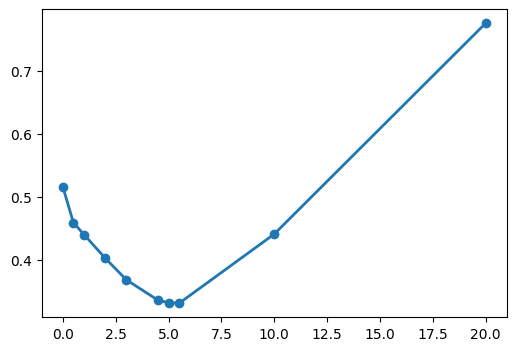

In [4]:
fine_df = refine_alpha(
    real_metrics, effects, make_landscape,
    coarse_best=coarse_best, step=0.5,
    depths=DEPTHS, n_per_depth=N_PER_DEPTH,
)
best_alpha = find_optimal_alpha(fine_df)
print(f"\nBest alpha: {best_alpha}")

all_sweep = pd.concat([coarse_df, fine_df]).drop_duplicates(subset="alpha").sort_values("alpha")
fig_alpha_calibration(all_sweep)

## Best-alpha comparison

In [ ]:
best_landscape = make_landscape(best_alpha)
best_synth_df = sample_synthetic_data(best_landscape, DEPTHS, n_per_depth=N_PER_DEPTH)
best_synth_metrics = compute_all_metrics(best_synth_df, effects, DEPTHS)

score = composite_validation_score(real_metrics, best_synth_metrics)
print(f"Best alpha: {best_alpha:.2f}, composite score: {score:.4f}\n")

print(f"{'Depth':>5} | {'Real corr':>9} | {'Synth corr':>10} | {'Real SE':>7} | {'Synth SE':>8}")
print("-" * 50)
for d in DEPTHS:
    rc = real_metrics["additive_correlation"].get(d, 0)
    sc = best_synth_metrics["additive_correlation"].get(d, 0)
    rse = real_metrics["sign_epistasis"].get(d, 0)
    sse = best_synth_metrics["sign_epistasis"].get(d, 0)
    print(f"{d:>5} | {rc:>9.3f} | {sc:>10.3f} | {rse:>7.3f} | {sse:>8.3f}")

## Figures

In [ ]:
# Collect metrics at a few alphas for multi-line plots
plot_alphas = sorted({0.0, 1.0, best_alpha, 5.0, 10.0})
synth_by_alpha = {}
for a in plot_alphas:
    ls = make_landscape(a)
    sdf = sample_synthetic_data(ls, DEPTHS, n_per_depth=N_PER_DEPTH)
    synth_by_alpha[a] = compute_all_metrics(sdf, effects, DEPTHS)
    print(f"  alpha={a:.2f} done")

In [ ]:
fig_additive_decay(real_metrics, synth_by_alpha, best_alpha, DEPTHS)

In [ ]:
fig_sign_epistasis(real_metrics, synth_by_alpha, best_alpha, DEPTHS)

In [ ]:
fig_deviation_distributions(real_metrics, best_synth_metrics, [2, 4, 6])

### Summary (paper figure)

In [ ]:
fig = fig_validation_summary(real_metrics, best_synth_metrics, best_alpha, DEPTHS)
save_fig(fig, "validation_summary", OUTPUT_DIR)

## Ablation: epistasis model comparison

In [ ]:
for model in ["random", "sign_consistent"]:
    print(f"\n=== {model} ===")
    build = lambda a, m=model: build_landscape(
        DMS_CSV, DISTANCES_NPZ, WT_FASTA,
        alpha=a, seed=SEED, epistasis_model=m,
    )
    sweep = alpha_sweep(
        real_metrics, effects, build,
        alphas=[0.0, 1.0, 3.0, 5.0, 10.0, 20.0],
        depths=DEPTHS, n_per_depth=N_PER_DEPTH,
    )
    best = find_optimal_alpha(sweep)
    best_score = sweep.loc[sweep["composite_score"].idxmin(), "composite_score"]
    print(f"  Best alpha: {best:.2f}, score: {best_score:.4f}")